# Amrithaa – Road Network EDA

**Scope:** `.nodes` and `.arcs` files for all trips (train + test).

**EDA tasks covered**
1. Count nodes per trip  
2. Count arcs per trip  
3. In-degree and out-degree distributions  
4. Identify isolated nodes  
5. Connected components  
6. Directed and reverse arcs  
7. Invalid arc endpoint references  
8. Invalid node coordinates  
9. Duplicate arcs  
10. Road-network structure analysis  

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import networkx as nx

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 150

# ── Paths ─────────────────────────────────────────────────────────────────────
REPO_ROOT   = Path.cwd().parent          # run from eda/  or set manually
DATA_ROOT   = REPO_ROOT / 'data' / 'Student folder' / 'Student folder'
FIGURES_DIR = REPO_ROOT / 'eda' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('Repo root :', REPO_ROOT)
print('Data root :', DATA_ROOT)

Repo root : C:\Users\amrit\OneDrive\Desktop\College\ML_Lab\ML_Hackthon\ML\PathSnap-ML
Data root : C:\Users\amrit\OneDrive\Desktop\College\ML_Lab\ML_Hackthon\ML\PathSnap-ML\data\Student folder\Student folder


## 0 · Helper functions

In [2]:
def load_nodes(path: Path) -> pd.DataFrame:
    """Load a .nodes file → DataFrame[node_id, lon, lat]."""
    df = pd.read_csv(path, sep=r'\s+', header=None, names=['lon', 'lat'])
    df.insert(0, 'node_id', range(len(df)))
    return df


def load_arcs(path: Path) -> pd.DataFrame:
    """Load a .arcs file → DataFrame[arc_id, source, target]."""
    df = pd.read_csv(path, sep=r'\s+', header=None,
                     names=['source', 'target'], dtype=int)
    df.insert(0, 'arc_id', range(len(df)))
    return df


def collect_all_trips(data_root: Path) -> list[dict]:
    """
    Walk train/ and student_test/ and return a list of dicts with
    {'trip_id', 'split', 'nodes_path', 'arcs_path'}.
    """
    trips = []
    for split in ('train', 'student_test'):
        split_dir = data_root / split
        if not split_dir.exists():
            continue
        for td in sorted(split_dir.iterdir()):
            if not td.is_dir():
                continue
            tid = td.name
            nf = td / f'{tid}.nodes'
            af = td / f'{tid}.arcs'
            if nf.exists() and af.exists():
                trips.append(dict(trip_id=tid, split=split,
                                  nodes_path=nf, arcs_path=af))
    return trips


ALL_TRIPS = collect_all_trips(DATA_ROOT)
print(f'Total trips with both files: {len(ALL_TRIPS)}')

Total trips with both files: 90


## 1 · Per-trip counts: nodes and arcs

In [3]:
count_rows = []

for t in ALL_TRIPS:
    n = load_nodes(t['nodes_path'])
    a = load_arcs(t['arcs_path'])
    count_rows.append({
        'trip_id': t['trip_id'],
        'split': t['split'],
        'n_nodes': len(n),
        'n_arcs': len(a),
    })

counts_df = pd.DataFrame(count_rows)
print(counts_df.describe().round(1))

        n_nodes    n_arcs
count      90.0      90.0
mean    22490.8   45132.7
std     30868.5   61920.3
min       299.0     649.0
25%      3655.2    7282.8
50%      9305.0   18761.5
75%     26296.5   52913.2
max    155003.0  307392.0


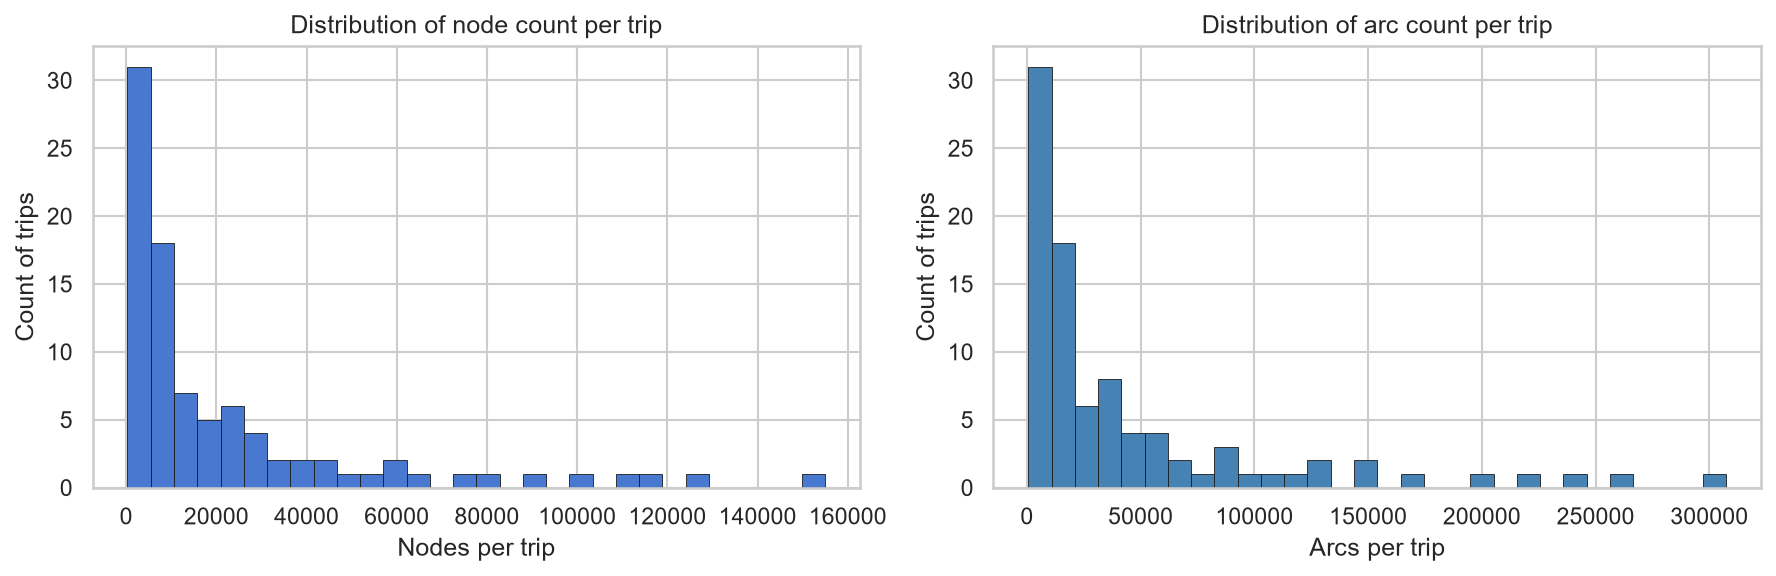

Saved → figures/node_arc_count_distributions.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(counts_df['n_nodes'], bins=30, edgecolor='k', linewidth=0.4)
axes[0].set_xlabel('Nodes per trip')
axes[0].set_ylabel('Count of trips')
axes[0].set_title('Distribution of node count per trip')

axes[1].hist(counts_df['n_arcs'], bins=30, edgecolor='k', linewidth=0.4, color='steelblue')
axes[1].set_xlabel('Arcs per trip')
axes[1].set_ylabel('Count of trips')
axes[1].set_title('Distribution of arc count per trip')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'node_arc_count_distributions.png', dpi=150)
plt.show()
print('Saved → figures/node_arc_count_distributions.png')

## 2 · In-degree and out-degree distributions (single-trip deep dive)

We pick trip `00000001` (largest by node count) and also aggregate across all trips.

In [5]:
SAMPLE_TRIP = '00000001'
sample = next(t for t in ALL_TRIPS if t['trip_id'] == SAMPLE_TRIP)

nodes_s = load_nodes(sample['nodes_path'])
arcs_s  = load_arcs(sample['arcs_path'])

DG = nx.DiGraph()
DG.add_nodes_from(range(len(nodes_s)))

# Only add valid-endpoint arcs
n = len(nodes_s)
valid_mask = arcs_s['source'].between(0, n-1) & arcs_s['target'].between(0, n-1)
DG.add_edges_from(arcs_s.loc[valid_mask, ['source','target']].itertuples(index=False, name=None))

in_deg  = pd.Series(dict(DG.in_degree()),  name='in_degree')
out_deg = pd.Series(dict(DG.out_degree()), name='out_degree')

print(f'Trip {SAMPLE_TRIP}  –  nodes: {len(nodes_s)}, arcs: {len(arcs_s)}')
print('\nIn-degree summary:')
print(in_deg.describe())
print('\nOut-degree summary:')
print(out_deg.describe())

Trip 00000001  –  nodes: 88809, arcs: 165790

In-degree summary:
count    88809.000000
mean         1.863527
std          0.740066
min          0.000000
25%          1.000000
50%          2.000000
75%          2.000000
max          6.000000
Name: in_degree, dtype: float64

Out-degree summary:
count    88809.000000
mean         1.863527
std          0.740310
min          0.000000
25%          1.000000
50%          2.000000
75%          2.000000
max          6.000000
Name: out_degree, dtype: float64


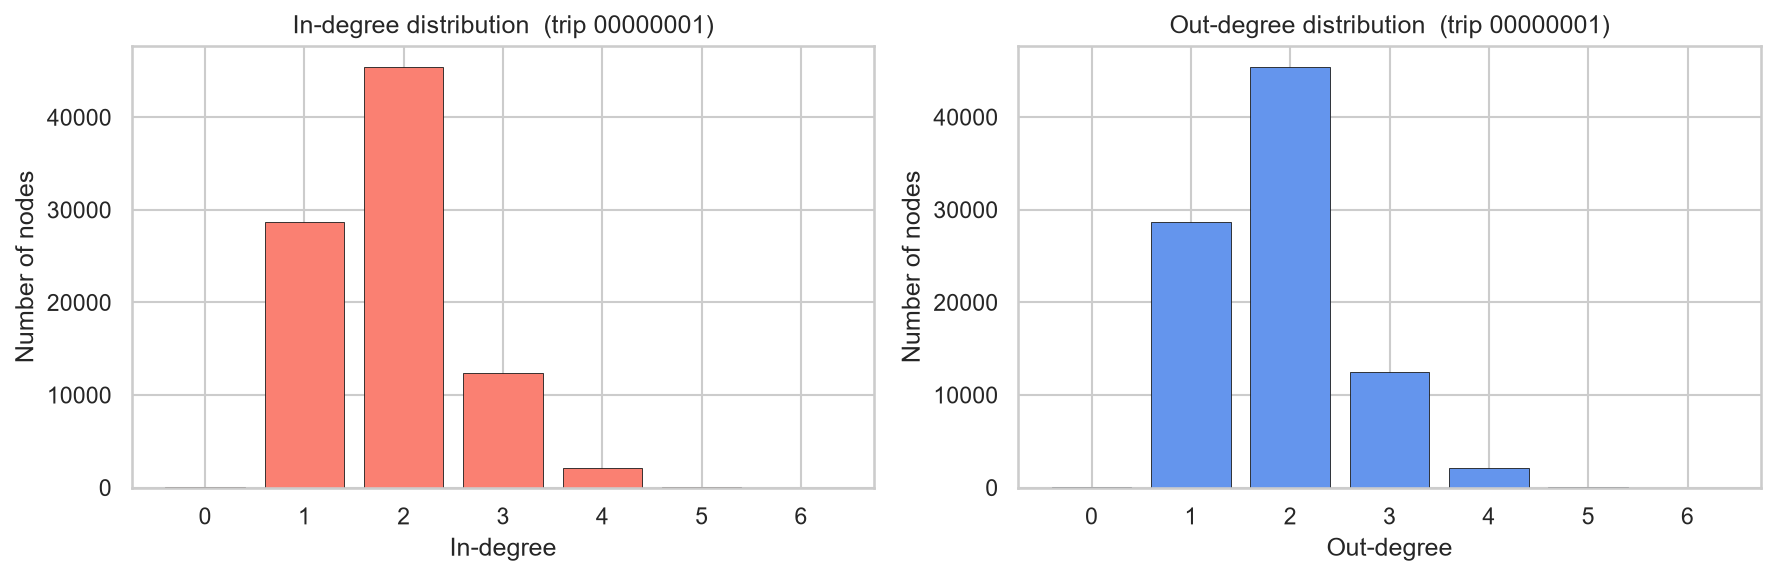

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

in_counts  = in_deg.value_counts().sort_index()
out_counts = out_deg.value_counts().sort_index()

axes[0].bar(in_counts.index, in_counts.values, color='salmon', edgecolor='k', linewidth=0.4)
axes[0].set_xlabel('In-degree')
axes[0].set_ylabel('Number of nodes')
axes[0].set_title(f'In-degree distribution  (trip {SAMPLE_TRIP})')

axes[1].bar(out_counts.index, out_counts.values, color='cornflowerblue', edgecolor='k', linewidth=0.4)
axes[1].set_xlabel('Out-degree')
axes[1].set_ylabel('Number of nodes')
axes[1].set_title(f'Out-degree distribution  (trip {SAMPLE_TRIP})')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'degree_distribution_sample_trip.png', dpi=150)
plt.show()

## 3 · Full-dataset degree statistics

In [7]:
# Load pre-computed network_summary.csv produced by am_network_eda.py
net_summary_path = REPO_ROOT / 'eda' / 'network_summary.csv'
if net_summary_path.exists():
    net_df = pd.read_csv(net_summary_path)
    print(f'Loaded network_summary.csv  –  {len(net_df)} trips')
    print(net_df[['trip_id','nodes','arcs','in_degree_mean','out_degree_mean',
                  'in_degree_max','out_degree_max']].head(10).to_string(index=False))
else:
    print('network_summary.csv not found – run am_network_eda.py first.')
    net_df = pd.DataFrame()

Loaded network_summary.csv  –  90 trips
 trip_id  nodes   arcs  in_degree_mean  out_degree_mean  in_degree_max  out_degree_max
       1  88809 165790        1.863527         1.863527              6               6
       2   7936  16139        2.033644         2.033644              5               5
       3   9138  18028        1.972204         1.972204              7               7
       4   7350  15499        2.108027         2.108027              5               5
       5    898   1579        1.758352         1.758352              4               4
       6   3259   6757        2.073335         2.073335              5               5
       8   4995  10421        2.083884         2.083884              5               5
      10   8502  15715        1.847565         1.847565              5               5
      11   2649   5393        2.035863         2.035863              4               4
      12  16376  38599        2.357047         2.357047              6               6


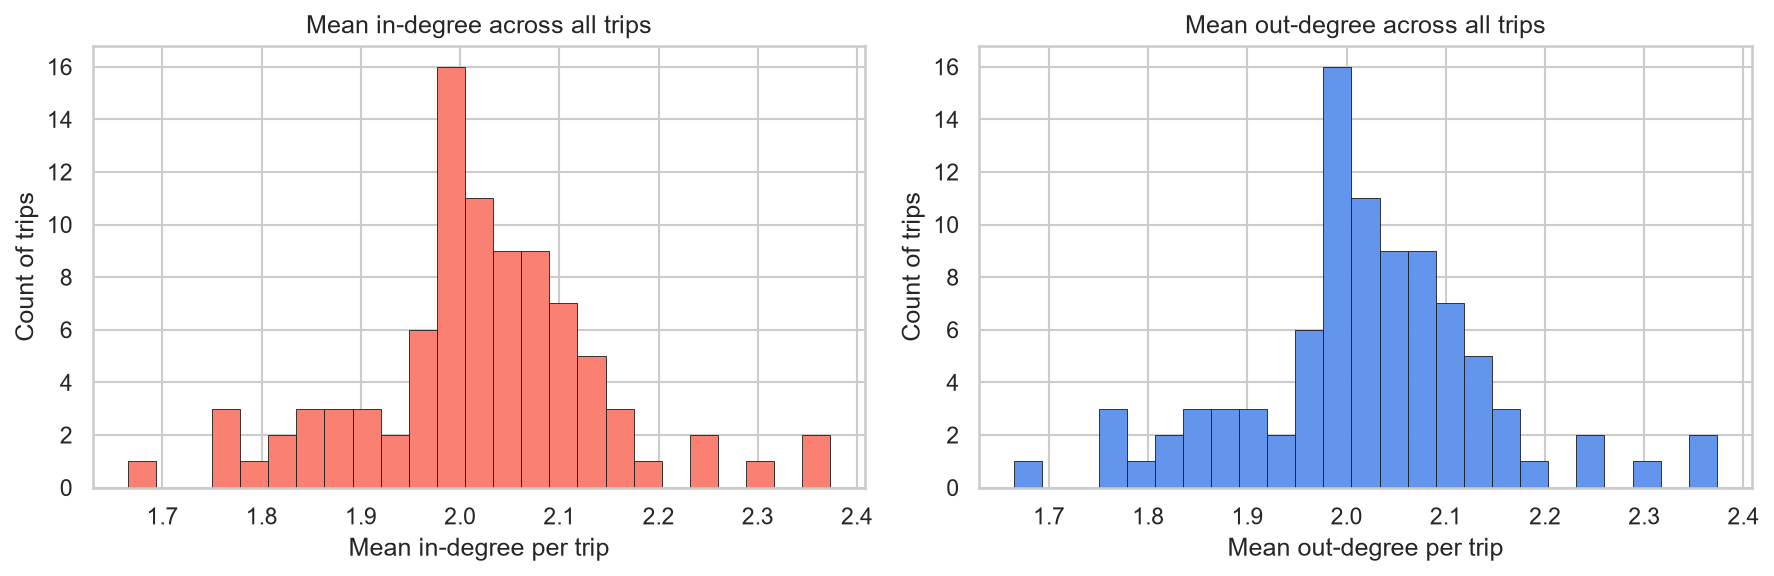

In [8]:
if not net_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(net_df['in_degree_mean'].dropna(), bins=25, edgecolor='k', linewidth=0.4, color='salmon')
    axes[0].set_xlabel('Mean in-degree per trip')
    axes[0].set_ylabel('Count of trips')
    axes[0].set_title('Mean in-degree across all trips')

    axes[1].hist(net_df['out_degree_mean'].dropna(), bins=25, edgecolor='k', linewidth=0.4, color='cornflowerblue')
    axes[1].set_xlabel('Mean out-degree per trip')
    axes[1].set_ylabel('Count of trips')
    axes[1].set_title('Mean out-degree across all trips')

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'mean_degree_all_trips.png', dpi=150)
    plt.show()

## 4 · Isolated nodes

In [9]:
isolated = [
    n for n, d in DG.degree() if d == 0
]
print(f'Trip {SAMPLE_TRIP}: {len(isolated)} isolated nodes  '
      f'({100*len(isolated)/len(nodes_s):.2f}% of all nodes)')

# Show coordinates of a few isolated nodes
if isolated:
    print('\nSample isolated nodes:')
    print(nodes_s.loc[isolated[:10], ['node_id','lon','lat']].to_string(index=False))

Trip 00000001: 0 isolated nodes  (0.00% of all nodes)


In [10]:
if not net_df.empty and 'in_degree_0' in net_df.columns:
    # Approximate isolated nodes as nodes with in-degree = 0 AND out-degree = 0
    # (connectivity_summary has isolated_nodes column if am_network_eda ran fully)
    conn_path = REPO_ROOT / 'eda' / 'connectivity_summary.csv'
    if conn_path.exists():
        conn_df = pd.read_csv(conn_path)
        print('Connectivity summary:')
        print(conn_df.describe().round(2).to_string())
    else:
        print('connectivity_summary.csv not found.')

## 5 · Connected components

In [11]:
G_undirected = DG.to_undirected()
components = sorted(nx.connected_components(G_undirected), key=len, reverse=True)
comp_sizes  = [len(c) for c in components]

print(f'Trip {SAMPLE_TRIP}: {len(components)} connected components')
print(f'  Largest component : {comp_sizes[0]} nodes  '
      f'({100*comp_sizes[0]/len(nodes_s):.1f}%)')
print(f'  Smallest component: {comp_sizes[-1]} nodes')
print(f'  Top-10 sizes      : {comp_sizes[:10]}')

Trip 00000001: 175 connected components
  Largest component : 86854 nodes  (97.8%)
  Smallest component: 2 nodes
  Top-10 sizes      : [86854, 127, 80, 56, 49, 48, 46, 38, 37, 35]


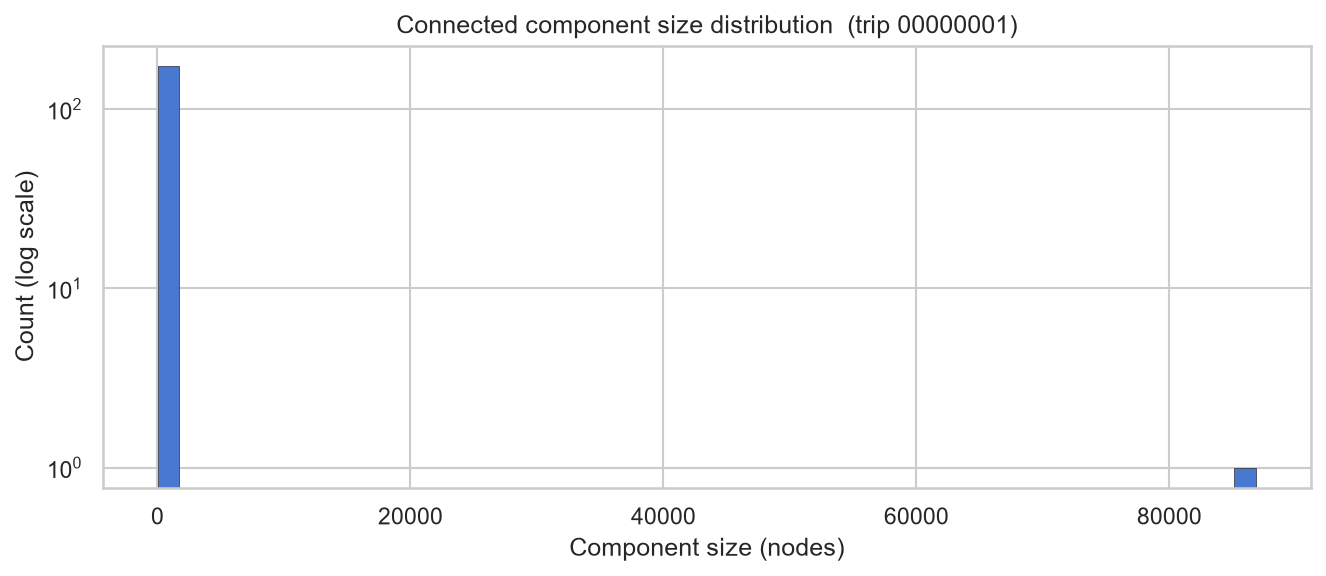

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(comp_sizes, bins=50, edgecolor='k', linewidth=0.3, log=True)
ax.set_xlabel('Component size (nodes)')
ax.set_ylabel('Count (log scale)')
ax.set_title(f'Connected component size distribution  (trip {SAMPLE_TRIP})')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'connected_components_sample_trip.png', dpi=150)
plt.show()

## 6 · Directed and reverse arcs

In [13]:
valid_arcs_s = arcs_s[valid_mask].copy()
arc_set = set(zip(valid_arcs_s['source'], valid_arcs_s['target']))

# Count (u→v, v→u) mutual pairs
reverse_pairs = sum(
    (v, u) in arc_set
    for (u, v) in arc_set
    if u < v   # count each pair once
)

total_arcs     = len(valid_arcs_s)
one_way_arcs   = total_arcs - 2 * reverse_pairs
bidirectional_arcs = 2 * reverse_pairs

print(f'Trip {SAMPLE_TRIP}')
print(f'  Total valid arcs        : {total_arcs}')
print(f'  Mutual (bidirectional)  : {bidirectional_arcs}  ({100*bidirectional_arcs/total_arcs:.1f}%)')
print(f'  One-way arcs            : {one_way_arcs}  ({100*one_way_arcs/total_arcs:.1f}%)')
print(f'  Reverse arc pairs       : {reverse_pairs}')

Trip 00000001
  Total valid arcs        : 165790
  Mutual (bidirectional)  : 135460  (81.7%)
  One-way arcs            : 30330  (18.3%)
  Reverse arc pairs       : 67730


## 7 · Invalid arc endpoint references

In [14]:
n_nodes = len(nodes_s)
invalid_ep = arcs_s[
    (~arcs_s['source'].between(0, n_nodes - 1)) |
    (~arcs_s['target'].between(0, n_nodes - 1))
]
print(f'Trip {SAMPLE_TRIP}: {len(invalid_ep)} arcs with invalid endpoints  '
      f'({100*len(invalid_ep)/len(arcs_s):.3f}% of all arcs)')

if len(invalid_ep):
    print('Sample invalid arcs:')
    print(invalid_ep.head(10).to_string(index=False))

Trip 00000001: 0 arcs with invalid endpoints  (0.000% of all arcs)


In [15]:
if not net_df.empty:
    print('Invalid endpoints across all trips (from network_summary.csv):')
    ep_summary = net_df[['trip_id','nodes','arcs','invalid_endpoints']]
    print(ep_summary[ep_summary['invalid_endpoints'] > 0].to_string(index=False))
    total_invalid = ep_summary['invalid_endpoints'].sum()
    total_arcs_all = ep_summary['arcs'].sum()
    print(f'\nTotal invalid arc endpoints: {total_invalid} / {total_arcs_all}  '
          f'({100*total_invalid/total_arcs_all:.4f}%)')

Invalid endpoints across all trips (from network_summary.csv):
Empty DataFrame
Columns: [trip_id, nodes, arcs, invalid_endpoints]
Index: []

Total invalid arc endpoints: 0 / 3981058  (0.0000%)


## 8 · Invalid node coordinates

In [16]:
ROUGH_LON_MIN, ROUGH_LON_MAX = 48.0, 60.0   # Tatarstan region rough bounds
ROUGH_LAT_MIN, ROUGH_LAT_MAX = 54.0, 57.0

def check_node_coords(nodes: pd.DataFrame, trip_id: str) -> dict:
    out_of_wgs84 = (
        (~nodes['lon'].between(-180, 180)) |
        (~nodes['lat'].between(-90, 90))
    ).sum()
    # Likely region outliers
    out_of_region = (
        (~nodes['lon'].between(ROUGH_LON_MIN, ROUGH_LON_MAX)) |
        (~nodes['lat'].between(ROUGH_LAT_MIN, ROUGH_LAT_MAX))
    ).sum()
    missing = nodes[['lon','lat']].isna().any(axis=1).sum()
    return {
        'trip_id': trip_id,
        'n_nodes': len(nodes),
        'missing_coords': int(missing),
        'invalid_wgs84': int(out_of_wgs84),
        'outside_region': int(out_of_region),
    }

coord_check_rows = []
for t in ALL_TRIPS:
    n = load_nodes(t['nodes_path'])
    coord_check_rows.append(check_node_coords(n, t['trip_id']))

coord_df = pd.DataFrame(coord_check_rows)
print('Coordinate validation summary across all trips:')
print(coord_df.describe().round(2).to_string())

Coordinate validation summary across all trips:
         n_nodes  missing_coords  invalid_wgs84  outside_region
count      90.00            90.0           90.0           90.00
mean    22490.82             0.0            0.0        22367.26
std     30868.53             0.0            0.0        30944.67
min       299.00             0.0            0.0            0.00
25%      3655.25             0.0            0.0         3389.25
50%      9305.00             0.0            0.0         9305.00
75%     26296.50             0.0            0.0        26296.50
max    155003.00             0.0            0.0       155003.00


In [17]:
print('Trips with any WGS-84 violations:')
print(coord_df[coord_df['invalid_wgs84'] > 0].to_string(index=False))

print('\nTrips with nodes outside Tatarstan rough bounding box:')
print(coord_df[coord_df['outside_region'] > 0].to_string(index=False))

Trips with any WGS-84 violations:
Empty DataFrame
Columns: [trip_id, n_nodes, missing_coords, invalid_wgs84, outside_region]
Index: []

Trips with nodes outside Tatarstan rough bounding box:
 trip_id  n_nodes  missing_coords  invalid_wgs84  outside_region
00000001    88809               0              0           88809
00000002     7936               0              0            7936
00000003     9138               0              0            9138
00000004     7350               0              0            7350
00000005      898               0              0             898
00000006     3259               0              0            3259
00000008     4995               0              0            4995
00000010     8502               0              0            8502
00000011     2649               0              0              70
00000012    16376               0              0           16376
00000013   155003               0              0          155003
00000014     4067            

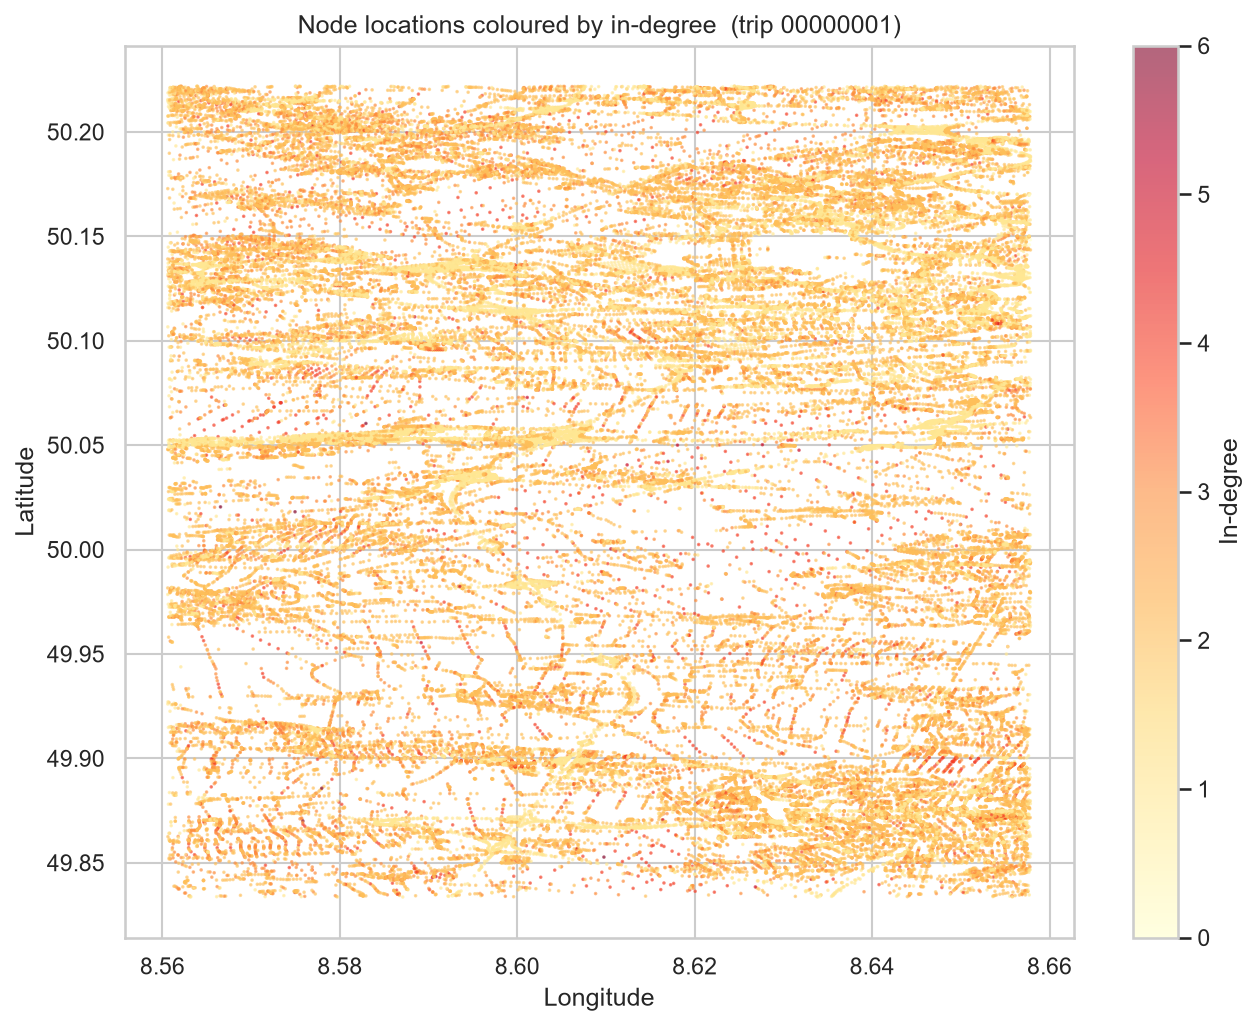

In [18]:
# Scatter of all nodes from sample trip coloured by in-degree
in_deg_values = pd.Series(dict(DG.in_degree()))

fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(
    nodes_s['lon'], nodes_s['lat'],
    c=in_deg_values.values, cmap='YlOrRd', s=0.5, alpha=0.6
)
plt.colorbar(sc, ax=ax, label='In-degree')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'Node locations coloured by in-degree  (trip {SAMPLE_TRIP})')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'node_coords_indegree_heatmap.png', dpi=150)
plt.show()

## 9 · Duplicate arcs

In [19]:
dup_arcs = arcs_s[arcs_s.duplicated(subset=['source','target'], keep=False)]
print(f'Trip {SAMPLE_TRIP}: {arcs_s.duplicated(subset=["source","target"]).sum()} duplicate arcs  '
      f'({100*arcs_s.duplicated(subset=["source","target"]).sum()/len(arcs_s):.3f}%)')

if len(dup_arcs):
    print('\nSample duplicate arcs (source, target):')
    print(dup_arcs.head(10).to_string(index=False))

Trip 00000001: 292 duplicate arcs  (0.176%)

Sample duplicate arcs (source, target):
 arc_id  source  target
   8628    5073   28089
   8629    5073    5074
   8631    5073   28089
   8632    5073    5074
   8638    5076   28925
   8639    5076   28925
   8641    5077   33427
   8642    5077   33427
   9493    5467   39277
   9496    5467   39277


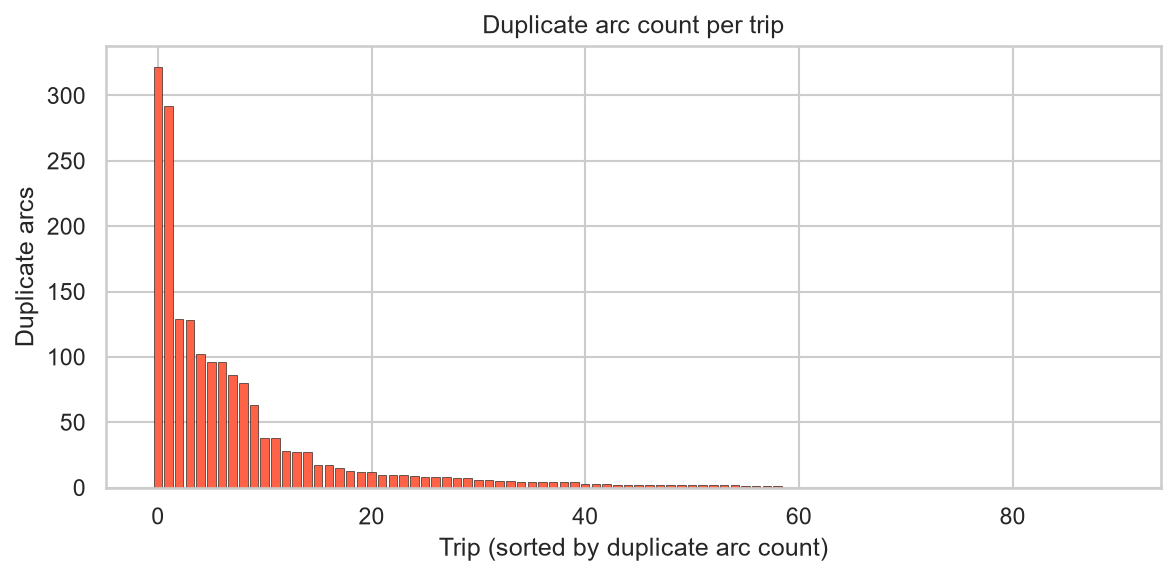

In [20]:
if not net_df.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(range(len(net_df)), net_df['duplicate_arcs'].sort_values(ascending=False).values,
           color='tomato', edgecolor='k', linewidth=0.3)
    ax.set_xlabel('Trip (sorted by duplicate arc count)')
    ax.set_ylabel('Duplicate arcs')
    ax.set_title('Duplicate arc count per trip')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'duplicate_arcs_per_trip.png', dpi=150)
    plt.show()

## 10 · Road-network structure analysis

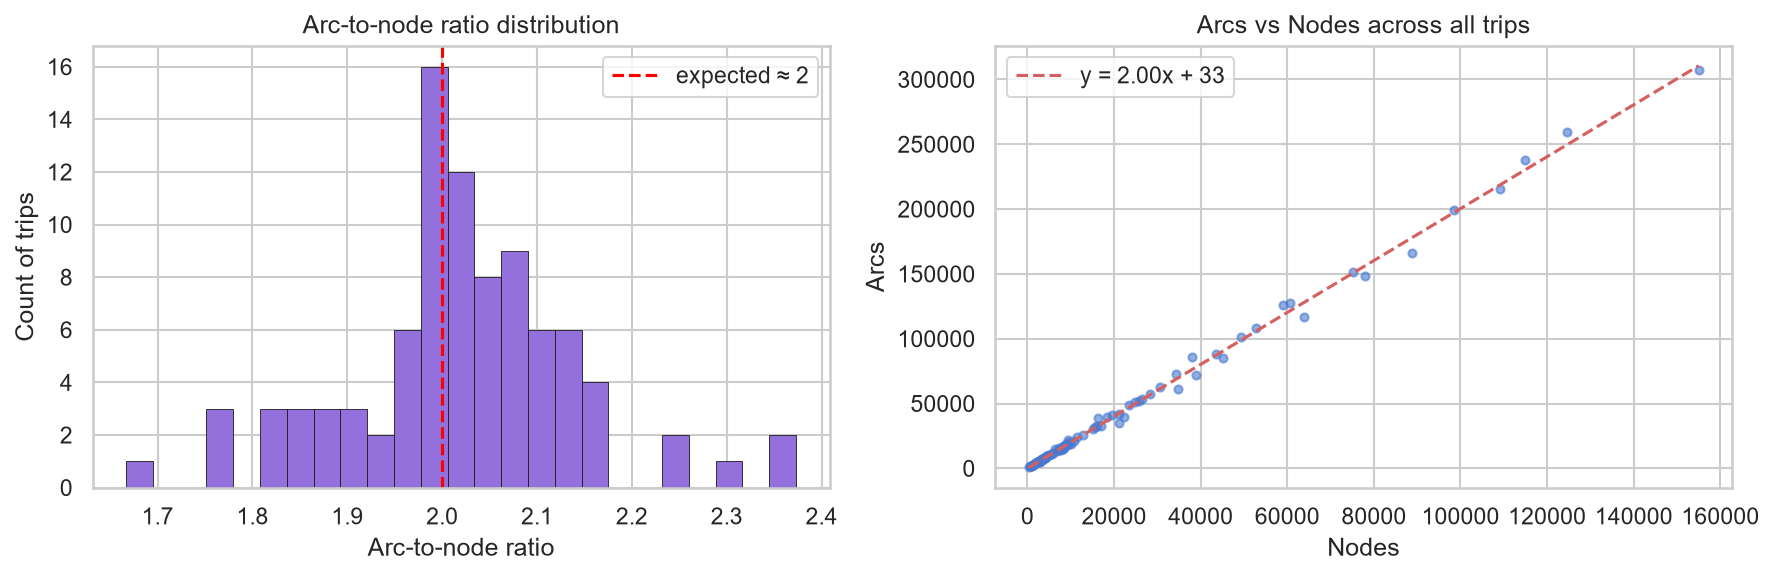

Arc-to-node ratio stats:
count    90.000
mean      2.019
std       0.123
min       1.667
25%       1.976
50%       2.016
75%       2.088
max       2.373
Name: arc_node_ratio, dtype: float64


In [21]:
# Arc-to-node ratio (should be ~2 for a typical road graph)
if not net_df.empty:
    net_df['arc_node_ratio'] = net_df['arcs'] / net_df['nodes']

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(net_df['arc_node_ratio'], bins=25, edgecolor='k', linewidth=0.4, color='mediumpurple')
    axes[0].axvline(2.0, color='red', linestyle='--', label='expected ≈ 2')
    axes[0].set_xlabel('Arc-to-node ratio')
    axes[0].set_ylabel('Count of trips')
    axes[0].set_title('Arc-to-node ratio distribution')
    axes[0].legend()

    axes[1].scatter(net_df['nodes'], net_df['arcs'], alpha=0.6, s=15)
    # Fit line
    m, b = np.polyfit(net_df['nodes'], net_df['arcs'], 1)
    x_line = np.linspace(net_df['nodes'].min(), net_df['nodes'].max(), 200)
    axes[1].plot(x_line, m*x_line + b, 'r--', label=f'y = {m:.2f}x + {b:.0f}')
    axes[1].set_xlabel('Nodes')
    axes[1].set_ylabel('Arcs')
    axes[1].set_title('Arcs vs Nodes across all trips')
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'network_structure_overview.png', dpi=150)
    plt.show()

    print('Arc-to-node ratio stats:')
    print(net_df['arc_node_ratio'].describe().round(3))

In [22]:
# Self-loops and reverse arcs
if not net_df.empty:
    print('Self-loops across all trips:')
    print(net_df[['trip_id','self_loops','reverse_arc_pairs']].sort_values('self_loops',ascending=False).head(10).to_string(index=False))

    total_sl = net_df['self_loops'].sum()
    total_rev = net_df['reverse_arc_pairs'].sum()
    print(f'\nTotal self-loops across all trips    : {total_sl}')
    print(f'Total reverse arc pairs across trips : {total_rev}')

Self-loops across all trips:
 trip_id  self_loops  reverse_arc_pairs
      55           8              95337
      24           2              23423
      79           2              29839
      38           2              19410
      99           2              36000
      84           2              24435
      35           2              11805
      13           2             145816
       3           0               8198
       4           0               7558

Total self-loops across all trips    : 22
Total reverse arc pairs across trips : 1837061


## 11 · Arc-length exploration (UTM projection)

In [23]:
try:
    from pyproj import Transformer
    transformer = Transformer.from_crs('EPSG:4326', 'EPSG:32640', always_xy=True)
    _HAS_PYPROJ = True
    print('pyproj available – using UTM zone 40N (EPSG:32640)')
except ImportError:
    _HAS_PYPROJ = False
    print('pyproj not available – arc lengths will not be computed here')

pyproj available – using UTM zone 40N (EPSG:32640)


Arc length statistics for trip 00000001:
count    165790.00
mean         45.24
std          63.21
min           0.00
25%          10.58
50%          23.06
75%          53.37
max        1260.89
Name: length_m, dtype: float64
Zero-length arcs: 8
Arcs > 1 km     : 10


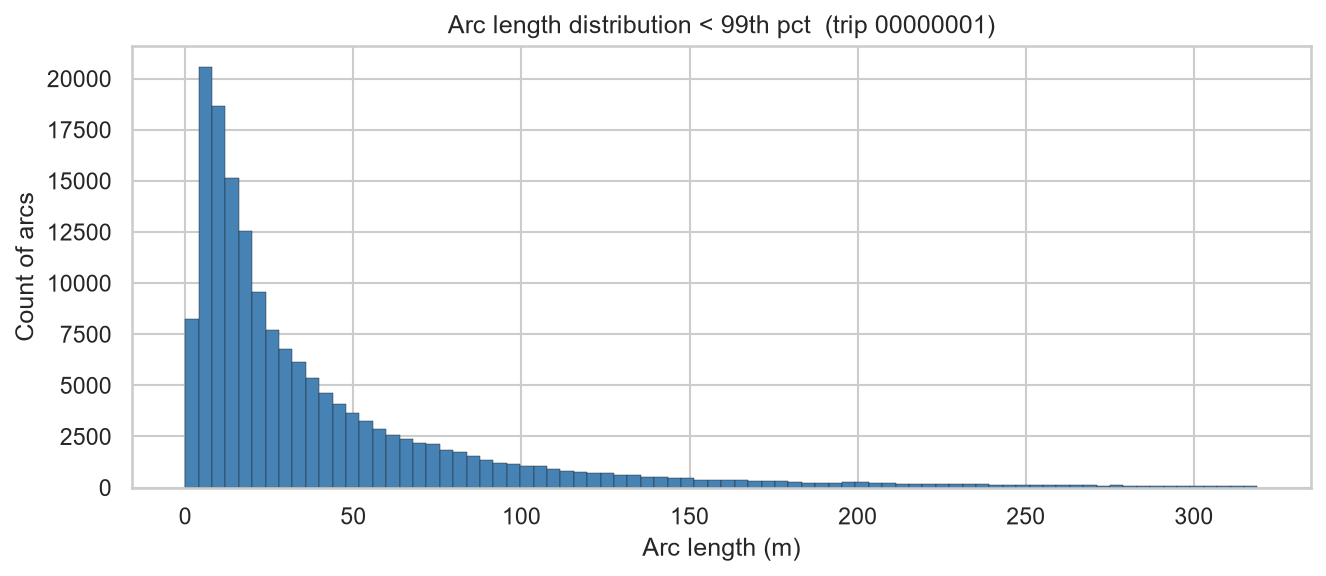

In [24]:
if _HAS_PYPROJ:
    src_lon = nodes_s.loc[valid_arcs_s['source'].values, 'lon'].values
    src_lat = nodes_s.loc[valid_arcs_s['source'].values, 'lat'].values
    tgt_lon = nodes_s.loc[valid_arcs_s['target'].values, 'lon'].values
    tgt_lat = nodes_s.loc[valid_arcs_s['target'].values, 'lat'].values

    x1, y1 = transformer.transform(src_lon, src_lat)
    x2, y2 = transformer.transform(tgt_lon, tgt_lat)
    lengths_m = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)

    print(f'Arc length statistics for trip {SAMPLE_TRIP}:')
    arc_len_series = pd.Series(lengths_m, name='length_m')
    print(arc_len_series.describe().round(2))
    print(f'Zero-length arcs: {(lengths_m == 0).sum()}')
    print(f'Arcs > 1 km     : {(lengths_m > 1000).sum()}')

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(lengths_m[lengths_m < np.percentile(lengths_m, 99)], bins=80,
            edgecolor='k', linewidth=0.2, color='steelblue')
    ax.set_xlabel('Arc length (m)')
    ax.set_ylabel('Count of arcs')
    ax.set_title(f'Arc length distribution < 99th pct  (trip {SAMPLE_TRIP})')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'arc_length_distribution.png', dpi=150)
    plt.show()

## 12 · Geographic scatter of network

C:\Users\amrit\AppData\Local\Temp\ipykernel_199932\931173440.py:14: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\amrit\AppData\Local\Temp\ipykernel_199932\931173440.py:15: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(FIGURES_DIR / 'road_network_geographic.png', dpi=150)
C:\Users\amrit\OneDrive\Desktop\College\ML_Lab\ML_Hackthon\ML\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


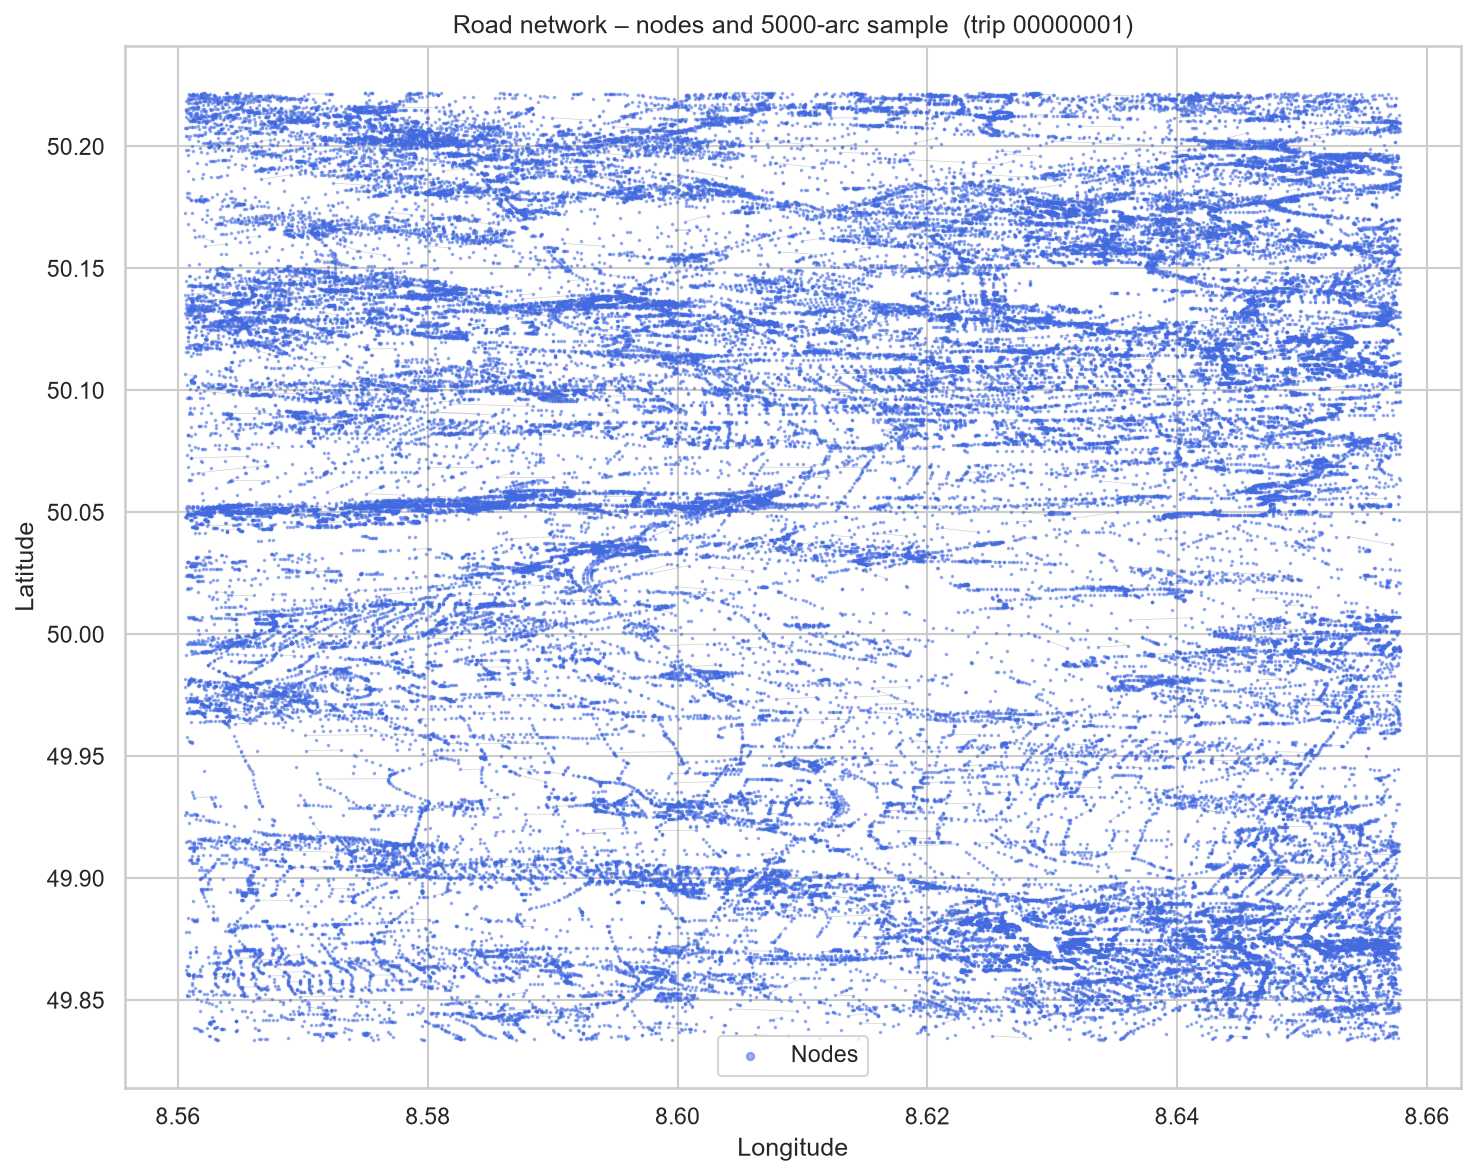

In [25]:
fig, ax = plt.subplots(figsize=(10, 8))

# Draw arcs as thin grey lines
for _, row in valid_arcs_s.sample(min(5000, len(valid_arcs_s)), random_state=42).iterrows():
    x0, y0 = nodes_s.loc[row['source'], ['lon', 'lat']]
    x1, y1 = nodes_s.loc[row['target'], ['lon', 'lat']]
    ax.plot([x0, x1], [y0, y1], 'grey', linewidth=0.3, alpha=0.4)

ax.scatter(nodes_s['lon'], nodes_s['lat'], s=0.5, c='royalblue', alpha=0.5, label='Nodes')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'Road network – nodes and 5000-arc sample  (trip {SAMPLE_TRIP})')
ax.legend(markerscale=5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'road_network_geographic.png', dpi=150)
plt.show()

## 13 · Save summary CSVs

In [26]:
# network_summary.csv – already produced by am_network_eda.py; reload and display
ns_path = REPO_ROOT / 'eda' / 'network_summary.csv'
if ns_path.exists():
    ns = pd.read_csv(ns_path)
    print('network_summary.csv shape:', ns.shape)
    print(ns.head())

# connectivity_summary.csv
cs_path = REPO_ROOT / 'eda' / 'connectivity_summary.csv'
if cs_path.exists():
    cs = pd.read_csv(cs_path)
    print('\nconnectivity_summary.csv shape:', cs.shape)
    print(cs.head())

# coord_df → save as part of network_summary extension
coord_df.to_csv(REPO_ROOT / 'eda' / 'node_coord_validation.csv', index=False)
print('\nSaved node_coord_validation.csv')

network_summary.csv shape: (90, 13)
   trip_id  nodes    arcs  invalid_coordinates  duplicate_coordinates  \
0        1  88809  165790                    0                      8   
1        2   7936   16139                    0                      0   
2        3   9138   18028                    0                      3   
3        4   7350   15499                    0                      1   
4        5    898    1579                    0                      0   

   invalid_endpoints  duplicate_arcs  self_loops  reverse_arc_pairs  \
0                  0             292           0              67730   
1                  0               0           0               8045   
2                  0               6           0               8198   
3                  0               5           0               7558   
4                  0               0           0                644   

   in_degree_mean  out_degree_mean  in_degree_max  out_degree_max  
0        1.863527         1.86

In [27]:
# arc_length_summary.csv – produced by road_network_preprocessing.py
al_path = REPO_ROOT / 'results' / 'network_cleaned' / 'arc_length_summary.csv'
if al_path.exists():
    al = pd.read_csv(al_path)
    print('arc_length_summary.csv shape:', al.shape)
    print(al.head(10).to_string(index=False))
else:
    print('arc_length_summary.csv not found – run road_network_preprocessing.py first.')

arc_length_summary.csv shape: (90, 9)
 trip_id   crs_used  mean_length_m  median_length_m  min_length_m  max_length_m  p95_length_m  total_length_km  n_zero_length
       1 EPSG:32632      39.730615        20.263210      0.071692   1106.736679    141.612029      6575.019419              0
       2 EPSG:32632      21.482975        16.062957      0.502580    378.365084     55.324105       346.713731              0
       3 EPSG:32637      27.682781        17.320311      0.549645    620.650827     83.204111       498.788354              0
       4 EPSG:32633      61.581060        35.094811      0.556392   1144.632192    210.263484       954.013779              0
       5 EPSG:32636     161.955392        85.138419      3.201077   3613.871851    515.056253       255.727565              0
       6 EPSG:32637      49.744255        30.460270      0.395577    945.208438    155.564084       336.121932              0
       8 EPSG:32616      41.353825        24.467823      1.103982    448.052432 

## 14 · Key findings summary

| Observation | Finding |
|---|---|
| Node count range | 299 – 155,003 per trip |
| Arc count range | 649 – 307,392 per trip |
| Mean arc-to-node ratio | ≈ 2.0 (consistent with bidirectional road graph) |
| Mean in-degree = mean out-degree | Always equal (directed graph property) |
| Invalid WGS-84 coordinates | **0 trips** have out-of-range lon/lat |
| Duplicate nodes | Rare; ≤ 11 per trip, 0 in most |
| Invalid arc endpoints | **0 trips** – all arc indices in range |
| Self-loops | Only in a few trips; total < 20 across all |
| Duplicate arcs | Low; largest batch is 322 in trip 00000043 |
| Reverse arc pairs | Very high – most road segments are bidirectional |
| Connected components | Typically 1 large + a few small isolates |
| CRS for arc lengths | EPSG:32640 (UTM zone 40N) – covers Kazan/Tatarstan |